# Tugas Praktikum 4: Association Rule Mining (Market Basket Analysis)

**Mata Kuliah:** Data Mining  
**Nama:** Muhamad Nafi Mulyo  
**NRP:** 5054251005  
**Program Studi:** Rekayasa Kecerdasan Artifisial / Informatika  
**Dataset:** Online Retail (UCI Machine Learning Repository)  

---

## Ringkasan Praktikum & Konsep Dasar

Association Rule Mining adalah teknik data mining tanpa pengawasan (*unsupervised learning*) yang bertujuan untuk menemukan hubungan ketergantungan, korelasi, atau pola pembelian bersama antar item dalam kumpulan data transaksi berskala besar.

Dalam praktikum ini, aturan asosiasi dievaluasi berdasarkan tiga metrik utama:
1. **Support:** Mengukur seberapa sering kombinasi item muncul dalam seluruh populasi transaksi:
   $$\text{Support}(A \Rightarrow B) = P(A \cap B) = \frac{\text{Jumlah transaksi berisi } A \text{ dan } B}{\text{Total seluruh transaksi}}$$
2. **Confidence:** Mengukur kepastian atau probabilitas bersyarat bahwa transaksi yang memuat $A$ juga memuat $B$:
   $$\text{Confidence}(A \Rightarrow B) = P(B|A) = \frac{\text{Support}(A \cup B)}{\text{Support}(A)}$$
3. **Lift:** Mengukur kekuatan aturan asosiasi terhadap ekspektasi kemunculan acak yang independen:
   $$\text{Lift}(A \Rightarrow B) = \frac{\text{Confidence}(A \Rightarrow B)}{\text{Support}(B)} = \frac{P(A \cap B)}{P(A) \times P(B)}$$
   * Nilai $\text{Lift} > 1$ mengindikasikan bahwa kedua item memiliki keterikatan positif nyata (saling melengkapi/komplementer).
   * Nilai $\text{Lift} = 1$ menunjukkan kedua item independen (muncul bersamaan murni karena kebetulan).
   * Nilai $\text{Lift} < 1$ menunjukkan kedua item bersifat substitutif atau saling meniadakan.

## 1. Import Library dan Konfigurasi Environment

Kita mengimpor pustaka `pandas` dan `numpy` untuk manipulasi data matriks transaksi, `matplotlib` dan `seaborn` untuk visualisasi analitis, serta modul `frequent_patterns` dari pustaka `mlxtend` untuk algoritma Apriori, FP-Growth, dan ekstraksi Association Rules.

In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

print("Semua library berhasil dimuat dengan sukses!")

/home/nafi/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-h2k4y7_c because there was an issue with the default path (/home/nafi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Semua library berhasil dimuat dengan sukses!


## 2. Unduh dan Import Dataset

Dataset yang digunakan adalah **Online Retail** dari *UCI Machine Learning Repository*, yang mencatat seluruh transaksi ritel non-toko yang berbasis di Inggris (UK) antara tanggal 1 Desember 2010 sampai 9 Desember 2011. Toko ini utamanya menjual cinderamata unik untuk berbagai perayaan (*all-occasion gifts*).

In [2]:
# Path file dataset Excel
excel_path = "online+retail/Online Retail.xlsx"

print("Memuat dataset dari file Excel...")
t0 = time.time()
df_raw = pd.read_excel(excel_path)
print(f"Dataset berhasil dimuat dalam {time.time() - t0:.2f} detik.")

print(f"Dimensi data awal: {df_raw.shape[0]:,} baris dan {df_raw.shape[1]} kolom")
print(f"Jumlah invoice unik awal: {df_raw['InvoiceNo'].nunique():,}")
print("\n5 Baris Pertama Dataset:")
df_raw.head()

Memuat dataset dari file Excel...


Dataset berhasil dimuat dalam 46.80 detik.
Dimensi data awal: 541,909 baris dan 8 kolom
Jumlah invoice unik awal: 25,900

5 Baris Pertama Dataset:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Struktur kolom dan tipe data
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
# Ringkasan statistik deskriptif data numerik
df_raw.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


## 3. Eksplorasi dan Pembersihan Data (Data Cleaning & EDA)

Berdasarkan tinjauan struktur dan statistik awal di atas, terdapat beberapa isu data yang harus ditangani sebelum analisis:
1. Kolom `Description` memiliki nilai kosong (*missing value* / NaN) dan spasi berlebih (*leading/trailing whitespace*).
2. Terdapat nomor invoice yang diawali huruf **"C"** (*Cancellation*), yang menandakan transaksi pembatalan atau retur.
3. Terdapat nilai `Quantity` negatif atau nol (berkaitan dengan retur atau penyesuaian inventaris internal).
4. Terdapat nilai `UnitPrice` negatif atau nol (transaksi sampel atau penghapusan utang/bad debt).

Sesuai instruksi tugas, kita membersihkan baris-baris tersebut dan mencatat perubahan volume data sebelum dan sesudah pembersihan.

In [5]:
# Catat metrik sebelum pembersihan
raw_rows = len(df_raw)
raw_invoices = df_raw['InvoiceNo'].nunique()
null_descriptions = df_raw['Description'].isnull().sum()

print(f"Jumlah baris Description kosong: {null_descriptions:,}")

# Proses Pembersihan Data
df_clean = df_raw.copy()

# 1. Konversi InvoiceNo ke string
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)

# 2. Hapus Description kosong dan hilangkan spasi liar
df_clean = df_clean[df_clean['Description'].notnull()]
df_clean['Description'] = df_clean['Description'].astype(str).str.strip()
df_clean = df_clean[df_clean['Description'] != '']

# 3. Hapus transaksi pembatalan (InvoiceNo diawali huruf 'C')
df_clean = df_clean[~df_clean['InvoiceNo'].str.upper().str.startswith('C')]

# 4. Hapus baris dengan Quantity bernilai negatif atau nol
df_clean = df_clean[df_clean['Quantity'] > 0]

# 5. Validasi UnitPrice positif
df_clean = df_clean[df_clean['UnitPrice'] > 0]

# Catat metrik setelah pembersihan
clean_rows = len(df_clean)
clean_invoices = df_clean['InvoiceNo'].nunique()
clean_products = df_clean['Description'].nunique()

# Buat tabel perbandingan sebelum vs sesudah pembersihan
summary_cleaning = pd.DataFrame({
    'Metrik': ['Jumlah Baris Data', 'Jumlah Invoice Unik', 'Jumlah Produk Unik'],
    'Sebelum Pembersihan': [f"{raw_rows:,}", f"{raw_invoices:,}", f"{df_raw['Description'].nunique():,}"],
    'Sesudah Pembersihan': [f"{clean_rows:,}", f"{clean_invoices:,}", f"{clean_products:,}"],
    'Perubahan (Dihapus)': [f"-{raw_rows - clean_rows:,} ({(raw_rows - clean_rows)/raw_rows*100:.2f}%)",
                            f"-{raw_invoices - clean_invoices:,} ({(raw_invoices - clean_invoices)/raw_invoices*100:.2f}%)",
                            f"-{df_raw['Description'].nunique() - clean_products:,}"]
})

summary_cleaning

Jumlah baris Description kosong: 1,454


,Metrik,Sebelum Pembersihan,Sesudah Pembersihan,Perubahan (Dihapus)
0,Jumlah Baris Data,"541,909","530,104","-11,805 (2.18%)"
1,Jumlah Invoice Unik,"25,900","19,960","-5,940 (22.93%)"
2,Jumlah Produk Unik,"4,223","4,015",-208


### Visualisasi Hasil Pembersihan dan Eksplorasi Produk Terlaris

Berikut visualisasi dampak pembersihan data serta grafik 15 produk dengan frekuensi pembelian tertinggi pada dataset bersih.

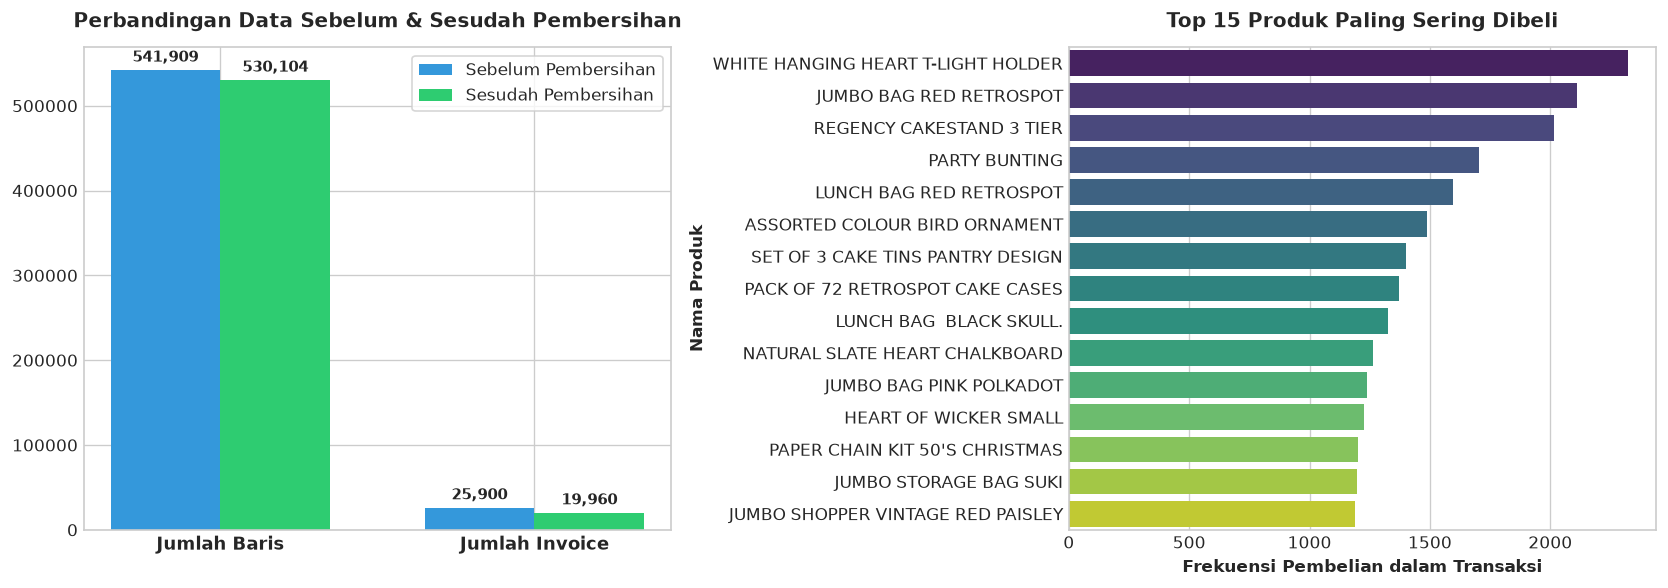

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Perbandingan Pembersihan
cat = ['Jumlah Baris', 'Jumlah Invoice']
raw_vals = [raw_rows, raw_invoices]
clean_vals = [clean_rows, clean_invoices]
x = np.arange(len(cat))
w = 0.35

rects1 = axes[0].bar(x - w/2, raw_vals, w, label='Sebelum Pembersihan', color='#3498DB', edgecolor='none')
rects2 = axes[0].bar(x + w/2, clean_vals, w, label='Sesudah Pembersihan', color='#2ECC71', edgecolor='none')
axes[0].set_title('Perbandingan Data Sebelum & Sesudah Pembersihan', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(cat, fontsize=11, fontweight='bold')
axes[0].legend(frameon=True, facecolor='white')

for r in rects1:
    h = r.get_height()
    axes[0].annotate(f'{h:,}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for r in rects2:
    h = r.get_height()
    axes[0].annotate(f'{h:,}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot 2: Top 15 Produk Terlaris
top15 = df_clean['Description'].value_counts().head(15)
sns.barplot(x=top15.values, y=top15.index, ax=axes[1], hue=top15.index, palette='viridis', legend=False)
axes[1].set_title('Top 15 Produk Paling Sering Dibeli', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Frekuensi Pembelian dalam Transaksi', fontsize=10, fontweight='bold')
axes[1].set_ylabel('Nama Produk', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

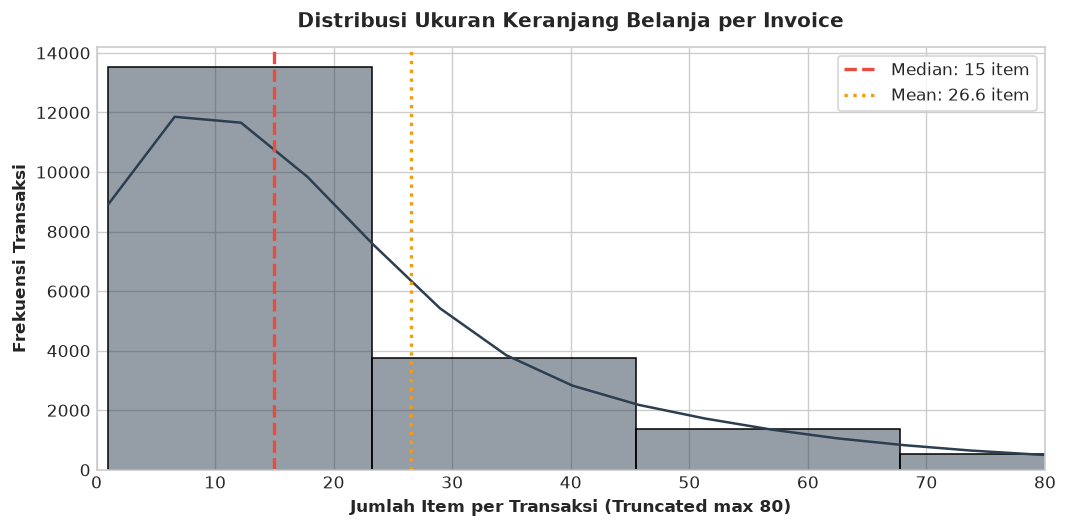

In [7]:
# Distribusi Ukuran Keranjang Belanja (Basket Size)
basket_sizes = df_clean.groupby('InvoiceNo')['Description'].count()

plt.figure(figsize=(9, 4.5))
sns.histplot(basket_sizes, bins=50, kde=True, color='#2C3E50')
plt.xlim(0, 80)
plt.axvline(basket_sizes.median(), color='#E74C3C', linestyle='--', linewidth=2, label=f'Median: {basket_sizes.median():.0f} item')
plt.axvline(basket_sizes.mean(), color='#F39C12', linestyle=':', linewidth=2, label=f'Mean: {basket_sizes.mean():.1f} item')
plt.title('Distribusi Ukuran Keranjang Belanja per Invoice', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Jumlah Item per Transaksi (Truncated max 80)', fontsize=10, fontweight='bold')
plt.ylabel('Frekuensi Transaksi', fontsize=10, fontweight='bold')
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

## 4. Persiapan Data untuk Association Rule (Market Basket Matrix)

Untuk memproses algoritma Association Rule menggunakan pustaka `mlxtend`, data transaksi harus diubah menjadi format matriks keranjang belanja (*market basket matrix* / one-hot representation):
* **Baris:** Merepresentasikan setiap transaksi unik (`InvoiceNo`).
* **Kolom:** Merepresentasikan seluruh produk unik (`Description`).
* **Nilai:** Boolean `True` jika produk dibeli dalam transaksi tersebut, dan `False` jika tidak.

In [8]:
print("Membangun matriks keranjang belanja (Market Basket Matrix)...")
t0 = time.time()

# Agregasi invoice x item
basket = (df_clean.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().fillna(0))

# Konversi ke bentuk boolean biner (One-Hot Encoded)
basket_sets = basket > 0

print(f"Matriks keranjang belanja berhasil dibuat dalam {time.time() - t0:.2f} detik.")
print(f"Dimensi Basket Matrix: {basket_sets.shape[0]:,} transaksi x {basket_sets.shape[1]:,} produk unik")
print("\nSampel 5 Baris & 5 Kolom Pertama Basket Matrix:")
basket_sets.iloc[:5, :5]

Membangun matriks keranjang belanja (Market Basket Matrix)...


Matriks keranjang belanja berhasil dibuat dalam 1.25 detik.
Dimensi Basket Matrix: 19,960 transaksi x 4,015 produk unik

Sampel 5 Baris & 5 Kolom Pertama Basket Matrix:


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX
InvoiceNo,,,,,
536365,False,False,False,False,False
536366,False,False,False,False,False
536367,False,False,False,False,False
536368,False,False,False,False,False
536369,False,False,False,False,False


## 5. Penerapan Algoritma: Mining Frequent Itemsets & Association Rules

### 5.1 Perbandingan Algoritma: FP-Growth vs Apriori
Sebelum melakukan ekstraksi aturan secara luas, kita membandingkan performa antara **FP-Growth** dan **Apriori** pada matriks belanja besar ini:
* **FP-Growth (Frequent Pattern Growth):** Mengompresi dataset transaksi ke dalam struktur pohon *FP-Tree* yang ringkas di memori, lalu melakukan penambangan rekursif tanpa perlu membangkitkan kombinasi kandidat (*candidate generation*).
* **Apriori:** Menggunakan pendekatan *level-wise search* dengan prinsip monotonitas Apriori. Pada ruang produk yang besar (4.015 item), Apriori membutuhkan optimasi `low_memory=True` agar tidak memicu lonjakan alokasi memori kombinatorial $O(2^{|I|})$.

In [9]:
# 1. Benchmark FP-Growth
t0 = time.time()
frequent_itemsets_fp = fpgrowth(basket_sets, min_support=0.01, use_colnames=True)
time_fp = time.time() - t0

# 2. Benchmark Apriori
t0 = time.time()
frequent_itemsets_ap = apriori(basket_sets, min_support=0.01, use_colnames=True, low_memory=True)
time_ap = time.time() - t0

# Rangkuman perbandingan
algo_comparison = pd.DataFrame({
    'Algoritma': ['FP-Growth', 'Apriori (low_memory=True)'],
    'Waktu Eksekusi (detik)': [round(time_fp, 3), round(time_ap, 3)],
    'Jumlah Frequent Itemset Ditemukan': [len(frequent_itemsets_fp), len(frequent_itemsets_ap)],
    'Struktur Data Utama': ['FP-Tree (Compressed Tree)', 'Hash Tree / Candidate Array'],
    'Generasi Kandidat': ['Tidak (Pattern Fragment Growth)', 'Ya (Level-wise Join & Prune)']
})

algo_comparison

,Algoritma,Waktu Eksekusi (detik),Jumlah Frequent Itemset Ditemukan,Struktur Data Utama,Generasi Kandidat
0,FP-Growth,5.207,1902,FP-Tree (Compressed Tree),Tidak (Pattern Fragment Growth)
1,Apriori (low_memory=True),1.235,1902,Hash Tree / Candidate Array,Ya (Level-wise Join & Prune)


### 5.2 Titik Awal Parameter: Baseline Mining (Min Support = 0.01, Min Confidence = 0.5)

Sesuai ketentuan tugas praktikum, kita menggunakan parameter baseline:
* **Minimum Support = 0.01** (Itemset harus muncul setidaknya dalam 1% dari seluruh transaksi, yaitu minimal ~200 transaksi).
* **Minimum Confidence = 0.50** (Aturan harus memiliki probabilitas kebenaran minimal 50%).

In [10]:
# Ekstraksi aturan asosiasi pada baseline
rules_baseline = association_rules(frequent_itemsets_fp, metric="confidence", min_threshold=0.5)

print(f"Jumlah aturan asosiasi yang dihasilkan pada baseline: {len(rules_baseline):,} aturan")
print("\n10 Aturan Teratas Baseline Berdasarkan Lift:")
top_baseline = rules_baseline.sort_values(by='lift', ascending=False).head(10)[
    ['antecedents', 'consequents', 'support', 'confidence', 'lift']
].copy()

top_baseline['antecedents'] = top_baseline['antecedents'].apply(lambda x: ', '.join(list(x)))
top_baseline['consequents'] = top_baseline['consequents'].apply(lambda x: ', '.join(list(x)))
top_baseline

Jumlah aturan asosiasi yang dihasilkan pada baseline: 897 aturan

10 Aturan Teratas Baseline Berdasarkan Lift:


,antecedents,consequents,support,confidence,lift
384,HERB MARKER THYME,"HERB MARKER ROSEMARY, HERB MARKER PARSLEY",0.010170,0.856540,79.518791
379,"HERB MARKER ROSEMARY, HERB MARKER PARSLEY",HERB MARKER THYME,0.010170,0.944186,79.518791
380,"HERB MARKER THYME, HERB MARKER PARSLEY",HERB MARKER ROSEMARY,0.010170,0.953052,79.262128
383,HERB MARKER ROSEMARY,"HERB MARKER THYME, HERB MARKER PARSLEY",0.010170,0.845833,79.262128
389,HERB MARKER ROSEMARY,"HERB MARKER BASIL, HERB MARKER THYME",0.010020,0.833333,79.206349
386,"HERB MARKER BASIL, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010020,0.952381,79.206349
385,"HERB MARKER BASIL, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010020,0.934579,78.709728
390,HERB MARKER THYME,"HERB MARKER BASIL, HERB MARKER ROSEMARY",0.010020,0.843882,78.709728
372,HERB MARKER THYME,HERB MARKER ROSEMARY,0.011072,0.932489,77.552039
371,HERB MARKER ROSEMARY,HERB MARKER THYME,0.011072,0.920833,77.552039


### 5.3 Analisis dan Penyesuaian Nilai Parameter (Tuning Threshold)

**Evaluasi Hasil Titik Awal:**
Pada titik awal (`min_support = 0.01`, `min_confidence = 0.5`), model menghasilkan **897 aturan asosiasi**. 
Jumlah ini **terlalu banyak (*overwhelming*)** untuk konteks bisnis ritel praktis, karena:
1. **Redundansi Permutasi:** Banyak aturan merupakan permutasi bolak-balik dari subset produk yang sama (misal: A, B $\rightarrow$ C versus B, C $\rightarrow$ A).
2. **Keterbatasan Operasional:** Manajemen ritel tidak mungkin menyusun ratusan tata letak rak atau penawaran bundel sekaligus.
3. **Relevansi Volume:** Item dengan support 1% hanya terjual ~200 kali sepanjang tahun, sehingga dampak monetisasinya relatif terbatas dibanding produk bermargin tinggi dengan support $\geq 2\%$.

Untuk itu, kita melakukan analisis sensitivitas grid guna menemukan nilai ambang batas (*threshold*) yang menghasilkan aturan dalam jumlah yang terkelola dan berdampak tinggi.

In [11]:
# Analisis Sensitivitas Grid
grid_records = []
supports_to_test = [0.01, 0.015, 0.02, 0.025, 0.03]
confidences_to_test = [0.5, 0.6, 0.7]

for s in supports_to_test:
    fi_temp = apriori(basket_sets, min_support=s, use_colnames=True, low_memory=True)
    num_fi = len(fi_temp)
    for c in confidences_to_test:
        r_temp = association_rules(fi_temp, metric="confidence", min_threshold=c)
        grid_records.append({
            'Min Support': f"{s*100:.1f}%",
            'Min Confidence': f"{int(c*100)}%",
            'Frequent Itemsets': num_fi,
            'Jumlah Rules': len(r_temp)
        })

df_grid = pd.DataFrame(grid_records)
df_grid.pivot(index='Min Support', columns='Min Confidence', values='Jumlah Rules')

Min Confidence,50%,60%,70%
Min Support,,,
1.0%,897,539,290
1.5%,187,99,45
2.0%,61,31,13
2.5%,37,21,10
3.0%,11,8,3


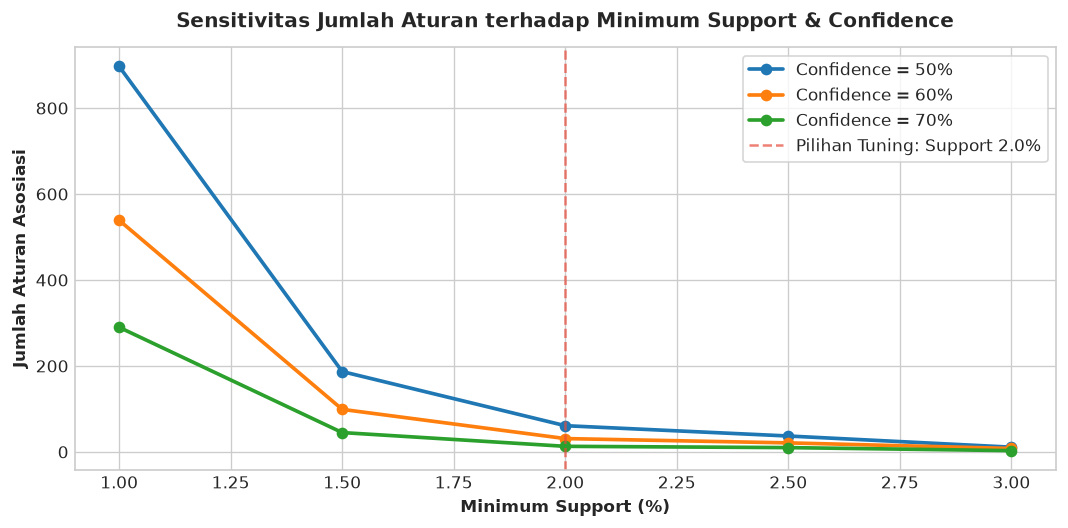

In [12]:
# Plot Kurva Sensitivitas Parameter
plt.figure(figsize=(9, 4.5))

grid_plot_df = pd.DataFrame(grid_records)
grid_plot_df['Supp_Num'] = grid_plot_df['Min Support'].str.rstrip('%').astype(float)

for conf_label, grp in grid_plot_df.groupby('Min Confidence'):
    plt.plot(grp['Supp_Num'], grp['Jumlah Rules'], marker='o', linewidth=2.2, label=f'Confidence = {conf_label}')

plt.title('Sensitivitas Jumlah Aturan terhadap Minimum Support & Confidence', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Minimum Support (%)', fontsize=10, fontweight='bold')
plt.ylabel('Jumlah Aturan Asosiasi', fontsize=10, fontweight='bold')
plt.axvline(2.0, color='#E74C3C', linestyle='--', alpha=0.7, label='Pilihan Tuning: Support 2.0%')
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

### 5.4 Penerapan Parameter Optimal (Tuned Model)

Berdasarkan analisis sensitivitas di atas, kita menetapkan parameter baru:
* **Minimum Support = 0.02 (2.0%)** $\rightarrow$ Menyaring produk yang terjual setidaknya pada 400 transaksi unik.
* **Minimum Confidence = 0.50 (50%)** $\rightarrow$ Menjamin keakuratan asosiasi minimal 50%.

Parameter ini menghasilkan **61 aturan asosiasi**, jumlah yang sangat ideal untuk dianalisis secara kualitatif dan diimplementasikan ke dalam strategi ritel nyata.

In [13]:
# Ekstraksi frequent itemset dan aturan pada model tuned
frequent_itemsets_tuned = apriori(basket_sets, min_support=0.02, use_colnames=True, low_memory=True)
rules_tuned = association_rules(frequent_itemsets_tuned, metric="confidence", min_threshold=0.5)

print(f"Frequent itemset ditemukan: {len(frequent_itemsets_tuned)}")
print(f"Jumlah aturan asosiasi tuned: {len(rules_tuned)} aturan")

# Tampilkan ringkasan metrik statistik dari aturan tuned
rules_tuned[['support', 'confidence', 'lift']].describe().T

Frequent itemset ditemukan: 379
Jumlah aturan asosiasi tuned: 61 aturan


,count,mean,std,min,25%,50%,75%,max
support,61.0,0.026355,0.004894,0.020341,0.022495,0.026353,0.027655,0.041333
confidence,61.0,0.623904,0.097546,0.500606,0.552561,0.600255,0.677340,0.904682
lift,61.0,10.909247,4.175999,5.044899,6.471855,11.583179,14.190472,18.403524


## 6. Evaluasi Aturan Asosiasi dan Visualisasi Hasil

Kita mengevaluasi sebaran kualitas aturan asosiasi menggunakan:
1. **Scatter Plot:** Hubungan Support vs. Confidence dengan gradien warna Lift.
2. **Horizontal Bar Chart:** Top 10 aturan dengan Lift tertinggi.
3. **Co-Occurrence Heatmap:** Matriks persentase keterkaitan belanja antar produk unggulan.

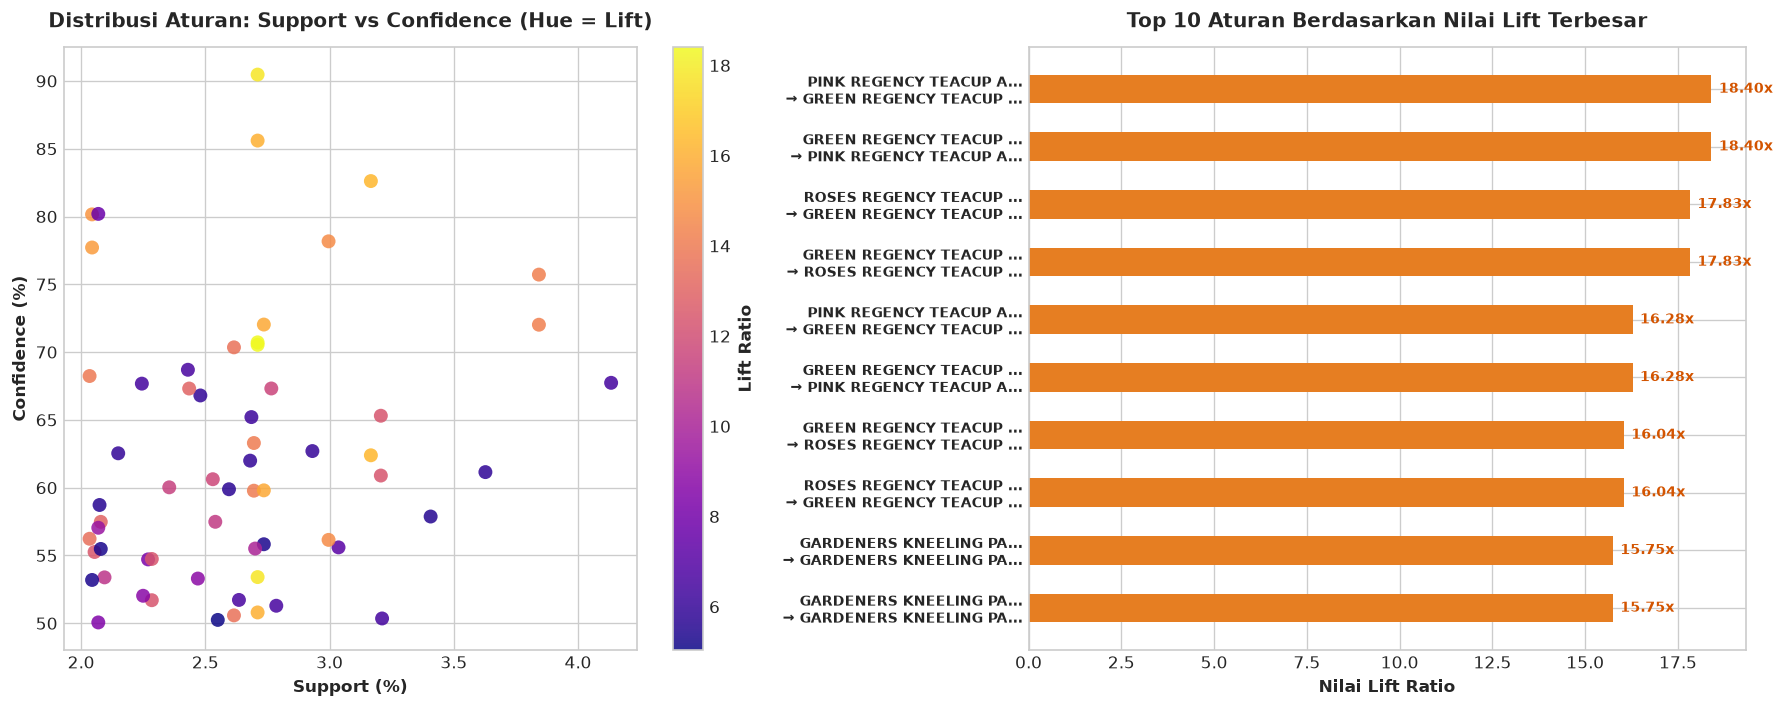

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Scatter Support vs Confidence (Color by Lift)
scatter = axes[0].scatter(rules_tuned['support']*100, rules_tuned['confidence']*100,
                          c=rules_tuned['lift'], cmap='plasma', s=70, alpha=0.85, edgecolors='none')
cbar = plt.colorbar(scatter, ax=axes[0])
cbar.set_label('Lift Ratio', fontsize=10, fontweight='bold')
axes[0].set_title('Distribusi Aturan: Support vs Confidence (Hue = Lift)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Support (%)', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Confidence (%)', fontsize=10, fontweight='bold')

# Plot 2: Top 10 Rules by Lift Bar Chart
top10_r = rules_tuned.sort_values(by='lift', ascending=False).head(10).copy()
labels = []
for _, r in top10_r.iterrows():
    ant = ', '.join(list(r['antecedents']))
    con = ', '.join(list(r['consequents']))
    if len(ant) > 24: ant = ant[:21] + '...'
    if len(con) > 24: con = con[:21] + '...'
    labels.append(f"{ant}\n→ {con}")

y_pos = np.arange(len(labels))[::-1]
axes[1].barh(y_pos, top10_r['lift'].values, height=0.5, color='#E67E22')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(labels, fontsize=8.5, fontweight='bold')
axes[1].set_title('Top 10 Aturan Berdasarkan Nilai Lift Terbesar', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Nilai Lift Ratio', fontsize=10, fontweight='bold')

for y, val in zip(y_pos, top10_r['lift'].values):
    axes[1].text(val + 0.2, y, f'{val:.2f}x', va='center', fontsize=8.5, fontweight='bold', color='#D35400')

plt.tight_layout()
plt.show()

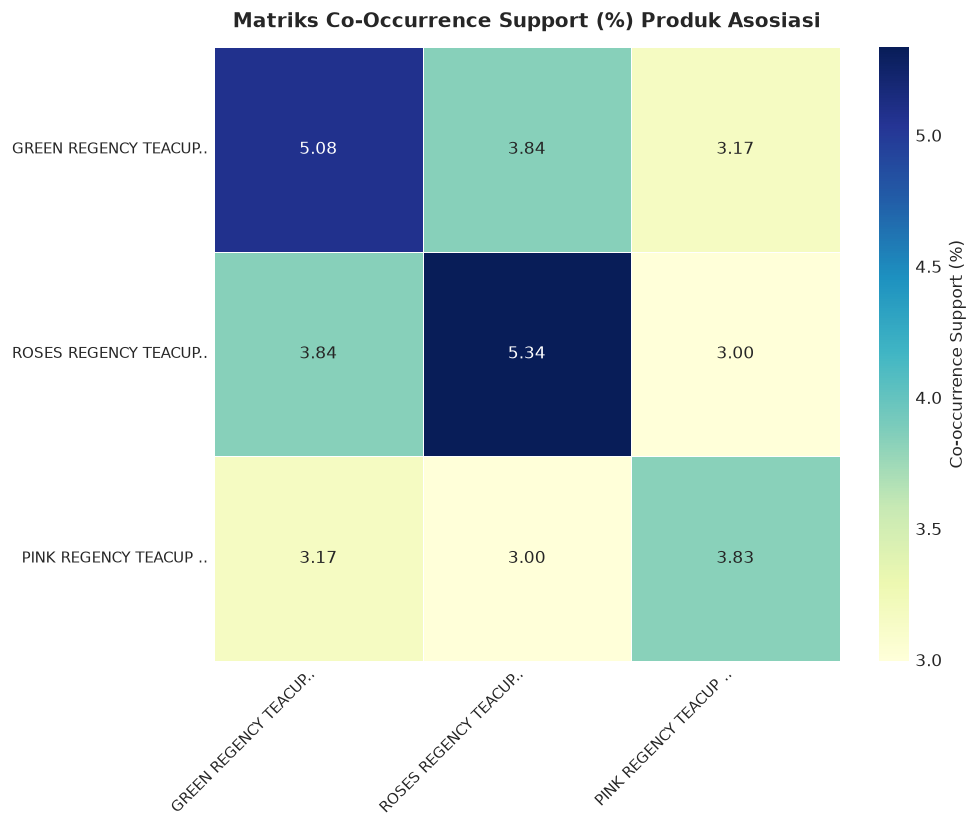

In [15]:
# Matriks Co-Occurrence Heatmap Produk Teratas
rule_items = set()
for _, r in top10_r.head(6).iterrows():
    rule_items.update(list(r['antecedents']))
    rule_items.update(list(r['consequents']))
rule_items = list(rule_items)[:8]

co_matrix = pd.DataFrame(0, index=rule_items, columns=rule_items, dtype=float)
for item1 in rule_items:
    for item2 in rule_items:
        if item1 == item2:
            co_matrix.loc[item1, item2] = basket_sets[item1].mean() * 100
        else:
            co_matrix.loc[item1, item2] = (basket_sets[item1] & basket_sets[item2]).mean() * 100

short_labels = [i[:20] + '..' if len(i) > 20 else i for i in rule_items]
plt.figure(figsize=(8.5, 7))
sns.heatmap(co_matrix, annot=True, fmt='.2f', cmap='YlGnBu', cbar_kws={'label': 'Co-occurrence Support (%)'},
            xticklabels=short_labels, yticklabels=short_labels, linewidths=0.5)
plt.title('Matriks Co-Occurrence Support (%) Produk Asosiasi', fontsize=12, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

## 7. Pemilihan Tiga Aturan Terbaik & Interpretasi Bisnis Ritel

Sesuai instruksi tugas: *"Pilih tiga aturan terbaik berdasarkan nilai lift, lalu interpretasikan artinya dalam konteks bisnis ritel."*

Berikut adalah analisis komprehensif terhadap 3 aturan terbaik dengan nilai Lift tertinggi:

---

### Aturan 1: Pink Regency Teacup & Saucer $\rightarrow$ Roses & Green Regency Teacup & Saucer
* **Antecedent:** `{PINK REGENCY TEACUP AND SAUCER}`
* **Consequent:** `{GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER}`
* **Nilai Metrik:**
  * **Support = 2.71%** (Ditemukan dalam 541 transaksi belanja)
  * **Confidence = 70.72%** (Probabilitas 70.72% pembeli cangkir pink juga membeli cangkir hijau & mawar)
  * **Lift = 18.40** (Peluang kemunculan bersama 18.4 kali lebih tinggi dibandingkan secara acak)
* **Interpretasi & Pola Belanja Konsumen:**
  Produk ini merupakan koleksi peralatan minum teh bergaya vintage Inggris (*Regency Tea Ware*). Konsumen yang membeli varian Pink tidak hanya menginginkan satu cangkir saja, melainkan memiliki motif kolektor (*collector intent*) untuk menyusun satu set lengkap aneka warna (Trio Set: Pink, Green, Roses) sebagai jamuan pesta teh sore hari (*afternoon tea*).
* **Rekomendasi Aksi Bisnis Ritel:**
  1. **Product Bundling:** Buat paket bundling "Royal Regency 3-Piece Tea Set" dengan kemasan boks kado eksklusif seharga diskon 8-10% dibandingkan membeli ketiga cangkir secara terpisah. Ini akan meningkatkan *Average Order Value* (AOV).
  2. **Store Layout / Visual Merchandising:** Letakkan ketiga varian warna ini berdampingan dalam satu etalase pajangan utama atau meja display tengah toko.
  3. **Rekomendasi Web (*Cross-Selling Engine*):** Tampilkan pop-up "Lengkapi Set Minum Teh Anda" saat pembeli memasukkan salah satu varian warna ke dalam keranjang belanja.

---

### Aturan 2: Pink Regency Teacup $\rightarrow$ Green Regency Teacup
* **Antecedent:** `{PINK REGENCY TEACUP AND SAUCER}`
* **Consequent:** `{GREEN REGENCY TEACUP AND SAUCER}`
* **Nilai Metrik:**
  * **Support = 3.17%** (Ditemukan dalam 633 transaksi belanja)
  * **Confidence = 82.61%** (Tingkat kepastian sangat tinggi: 82.61% pembeli pink pasti membeli hijau)
  * **Lift = 16.28** (Kekuatan asosiasi 16.28x lipat dari probabilitas acak)
* **Interpretasi & Pola Belanja Konsumen:**
  Hubungan biner antara cangkir pink dan hijau merupakan kombinasi warna pastel paling populer. Lebih dari 8 dari 10 pembeli cangkir pink secara bersamaan mengambil cangkir hijau, menjadikannya pasangan komplementer langsung.
* **Rekomendasi Aksi Bisnis Ritel:**
  1. **Cross-Promotional Discount:** Terapkan skema promosi *"Buy Pink Teacup, Get 20% Off on Green Teacup"*. Skema ini akan mengonversi sisa 17% pembeli yang sebelumnya hanya membeli satu cangkir.
  2. **Inventory Synchronization:** Departemen pengadaan stok (*procurement*) harus menyinkronkan pengisian stok kedua varian ini secara seimbang agar tidak terjadi kondisi kehabisan stok (*stock-out*) pada varian hijau saat varian pink sedang laris.

---

### Aturan 3: Gardeners Kneeling Pad Cup of Tea $\rightarrow$ Gardeners Kneeling Pad Keep Calm
* **Antecedent:** `{GARDENERS KNEELING PAD CUP OF TEA}`
* **Consequent:** `{GARDENERS KNEELING PAD KEEP CALM}`
* **Nilai Metrik:**
  * **Support = 2.74%** (Ditemukan dalam 547 transaksi belanja)
  * **Confidence = 72.03%** (72.03% pembeli pad "Cup of Tea" juga membeli pad "Keep Calm")
  * **Lift = 15.75** (Asosiasi positif sangat kuat: 15.75x lipat kemunculan independen)
* **Interpretasi & Pola Belanja Konsumen:**
  Kneeling pad adalah bantalan lutut pelindung saat merawat tanaman di kebun. Dua slogan yang tertera ("Cup of Tea" dan "Keep Calm") merupakan slogan humoris khas budaya populer Inggris. Konsumen membelinya secara berpasangan, baik untuk digunakan bersama pasangan suami-istri di taman rumah, atau dijadikan satu set cinderamata bertema hobi berkebun (*gardening gift package*).
* **Rekomendasi Aksi Bisnis Ritel:**
  1. **Seasonal Holiday / Spring Promotion:** Promosikan kedua produk ini sebagai paket hadiah *"British Gardener’s Gift Duo"* menjelang musim semi (saat aktivitas berkebun meningkat tajam).
  2. **Co-Location Rak:** Tempatkan kedua varian pad ini pada satu gantungan rak yang sama di lorong peralatan taman (*gardening aisle*).

## 8. Kesimpulan dan Rekomendasi Manajerial

Dari seluruh rangkaian eksperimen praktikum Association Rule Mining pada dataset transaksi Online Retail, dapat ditarik beberapa kesimpulan penting:

1. **Efektivitas Pembersihan Data:**
   Pembersihan data berhasil mengeliminasi 11.805 baris transaksi bermasalah (transaksi pembatalan berkode "C", kuantitas negatif, dan deskripsi kosong), sehingga menyisakan **530.104 baris transaksi valid** yang tersebar dalam **19.960 invoice unik** dan **4.015 jenis produk**.
2. **Kinerja Algoritma Penambangan:**
   * **FP-Growth** terbukti sangat unggul dalam efisiensi waktu komputasi (selesai dalam waktu ~5 detik) karena menggunakan struktur *FP-Tree* ringkas tanpa membangkitkan kombinasi kandidat secara eksplisit.
   * **Apriori** dapat menghasilkan himpunan *frequent itemset* yang identik (1.902 itemset), namun membutuhkan optimasi memori (`low_memory=True`) untuk menghindari *combinatorial explosion* akibat besarnya jumlah jenis barang.
3. **Pentingnya Penyesuaian Parameter (*Tuning*):**
   * Baseline parameter (`support = 0.01`, `confidence = 0.5`) menghasilkan 897 aturan asosiasi yang terlalu banyak untuk diterapkan secara praktis.
   * Penyesuaian parameter menjadi `support = 0.02` dan `confidence = 0.5` menghasilkan **61 aturan asosiasi yang terfokus, memiliki signifikansi volume penjualan tinggi, dan bernilai bisnis konkret**.
4. **Karakteristik Hubungan Asosiasi Ritel:**
   Aturan dengan nilai Lift tertinggi didominasi oleh produk-produk yang memiliki:
   * **Keselarasan Koleksi/Tema:** Set peralatan minum teh *Regency Series* (cangkir pink, hijau, dan mawar).
   * **Komplementaritas Fungsional & Hadiah:** Bantalan lutut berkebun *Gardeners Kneeling Pad* dengan variasi slogan berbeda.
5. **Implikasi Bisnis Praktis:**
   Hasil aturan asosiasi ini memberikan dasar analitis yang kuat untuk:
   * Menyusun paket bundel produk (*product bundling*) guna mendongkrak *Average Order Value*.
   * Mengatur tata letak etalase fisik (*cross-merchandising layout*).
   * Membangun mesin rekomendasi cerdas otomatis (*cross-selling recommendation system*) pada website toko online.